# Carteira de compra e retenção dos itens CS:GO

A carteira de compra e retenção é a referência de desempenho mais simples. Este caderno mede se
escolher itens pelo treino gera retorno líquido no teste. O resultado serve de base de comparação
para o modelo. A ordem segue a decisão: a seleção dos itens, o desempenho da carteira, a comparação com
referências e a composição da carteira.

In [1]:
from argparse import ArgumentParser
from pathlib import Path

import altair as alt
import polars as pl
from great_tables import GT
from helpers.export import inline_table_styles, write_outputs
from helpers.formatting import DEC_MARK, SEP_MARK, format_metric, metric_text_table
from helpers.params import load_params
from helpers.paths import repo
from helpers.portfolio import (
    asset_multiples,
    benchmark_paths,
    benchmark_summary,
    eligible_assets,
    hold_positions,
    item_contributions,
    k_sweep_summary,
    meets_thresholds,
    portfolio_rarity,
    portfolio_returns,
    portfolio_summary,
    threshold_pass_counts,
    training_candidates,
    with_training_ratios,
)
from helpers.runtime import notebook_arguments
from helpers.schemas import read_table

In [2]:
# GitHub shows PNG output but not Vega-Lite.
alt.renderers.enable("png")

# GitHub drops style blocks, so the tables keep their styles inline.
inline_table_styles()

WIDE_TABLES = frozenset({"portfolio_items"})

PORTFOLIO_LABELS = {
    "assets": "Itens",
    "days": "Dias de teste",
    "sale_fee": "Taxa de venda (%)",
    "roi": "ROI",
    "sharpe": "Sharpe",
    "sortino": "Sortino",
}

PORTFOLIO_FORMATS = {
    "assets": "d",
    "days": "d",
    "sale_fee": ".0f",
    "roi": ".2%",
    "sharpe": ".3f",
    "sortino": ".3f",
}

RARITY_COLUMNS = ["candidate_assets", "selected_assets"]

SHARE_COLUMNS = ["candidate_share", "selected_share"]

PATH_LABELS = {"selected": "Selecionada", "candidates": "Todos os candidatos", "eligible": "Todos os elegíveis"}

## Argumentos da linha de comando

In [3]:
portfolio_params = load_params()["portfolio"]

parser = ArgumentParser(description="Carteira de compra e retenção com pesos iguais.")
parser.add_argument("--prices", type=Path, default=repo() / "files/prices.parquet", help="Preços diários limpos.")
parser.add_argument("--k", type=int, default=10, help="Número de itens na carteira.")
parser.add_argument("--rank", choices=["roi", "sharpe", "sortino"], default="roi", help="Razão de treino.")
parser.add_argument("--roi", type=float, default=portfolio_params["min_roi"], help="ROI mínimo no treino.")
parser.add_argument("--sharpe", type=float, default=portfolio_params["min_sharpe"], help="Sharpe mínimo no treino.")
parser.add_argument("--sortino", type=float, default=portfolio_params["min_sortino"], help="Sortino mínimo no treino.")
parser.add_argument(
    "--buy-and-hold",
    type=Path,
    default=repo() / "files/buy_and_hold.parquet",
    help="Linhas diárias da carteira.",
)
parser.add_argument("--output", type=Path, default=repo() / "files/portfolio.parquet", help="Métricas da carteira.")
parser.add_argument("--tables", type=Path, default=repo() / "output/tables", help="Pasta para os arquivos das tabelas.")
parser.add_argument("--images", type=Path, default=repo() / "output/images", help="Pasta para os gráficos.")
args = parser.parse_args(notebook_arguments())

if args.k < 1:
    message = "k must be positive"
    raise SystemExit(message)

In [4]:
prices = read_table("prices", args.prices).sort("name", "date")
thresholds = {"roi": args.roi, "sharpe": args.sharpe, "sortino": args.sortino}

## Selecionar itens elegíveis nos dias de treino

A seleção usa apenas os dias de treino. Isso impede que informação do período de teste influencie
a carteira. Só entram itens com preço de 24 horas em até sete dias antes do primeiro dia de teste, pois
só eles podem ser comprados. Os preços de entrada, de saída e de treino são medianas dos últimos
preços observados, para que o ruído de um único preço não decida o ROI.

Os limites usam razões diárias sem anualização. Guede-Fernández et al. (2025) exigem Sharpe ≥ 1,
Sortino ≥ 2 e ROI ≥ 5% e não informam a frequência dos retornos, então os limites daqui, menores, não
são comparáveis aos deles. O custo de venda é 15% (5% da Steam e 10% do jogo), contra 10% no artigo. O
artigo mantém só itens com histórico diário completo. Este trabalho exige um mínimo de observações no
treino e não preenche preços. A tabela mostra quantos candidatos passam por cada limite.

In [5]:
candidates = training_candidates(prices)
selected = eligible_assets(candidates, args.k, args.rank, thresholds)
pass_counts = threshold_pass_counts(candidates, thresholds)

threshold_labels = {
    "candidates": "Candidatos com preço até sete dias antes do teste",
    "roi": f"ROI de treino ≥ {format_metric(args.roi, '.0%')}",
    "sharpe": f"Sharpe diário de treino ≥ {format_metric(args.sharpe, '.3f')}",
    "sortino": f"Sortino diário de treino ≥ {format_metric(args.sortino, '.3f')}",
    "all": "Os três limites juntos",
}

thresholds_gt = (
    GT(metric_text_table(pass_counts, threshold_labels, dict.fromkeys(threshold_labels, "d")))
    .tab_header(title="Candidatos que Passam pelos Limites de Treino — CS:GO")
    .cols_label(metric_name="Critério", metric_value="Itens")
    .tab_source_note(
        "Razões diárias, sem anualização. A carteira escolhe os melhores itens entre os que passam nos três limites."
    )
)
thresholds_gt

"Razões diárias, sem anualização. A carteira escolhe os melhores itens entre os que passam nos três limites."


## Comparar a raridade dos itens escolhidos com a dos candidatos

A tabela mostra se a seleção pelo treino concentra a carteira em uma raridade.

In [6]:
rarity = portfolio_rarity(candidates, selected, prices)

rarity_gt = (
    GT(rarity)
    .cols_align("left", columns="rarity")
    .tab_header(title="Raridade dos Itens da Carteira — CS:GO")
    .fmt_integer(columns=RARITY_COLUMNS, sep_mark=SEP_MARK)
    .fmt_percent(columns=SHARE_COLUMNS, decimals=1, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .cols_label(
        rarity="Raridade",
        candidate_assets="Candidatos",
        candidate_share="Parcela dos candidatos",
        selected_assets="Selecionados",
        selected_share="Parcela dos selecionados",
    )
    .tab_source_note("Candidatos: itens com preço até sete dias antes do primeiro dia de teste.")
)
rarity_gt

Candidatos: itens com preço até sete dias antes do primeiro dia de teste.


## Manter a carteira nos dias de teste e medir o desempenho

A carteira mantém os itens escolhidos sem rebalanceamento. O item que deixa de ter preço mantém o
último valor. Assim a carteira não inventa retornos nem encerra a posição antes do fim. ROI, Sharpe e
Sortino diários resumem o desempenho. A taxa de venda de 15% entra uma só vez, no último dia, porque a
estratégia vende apenas no final.

In [7]:
rows = portfolio_returns(hold_positions(prices, selected.select("name"), args.k))
metrics = portfolio_summary(rows, args.k)

portfolio_gt = (
    GT(metric_text_table(metrics, PORTFOLIO_LABELS, PORTFOLIO_FORMATS))
    .tab_header(title="Carteira de Compra e Retenção — CS:GO")
    .cols_label(metric_name="Métrica", metric_value="Valor")
    .tab_source_note(
        "Carteira igualmente ponderada nos dias de teste, sem rebalanceamento. "
        "Taxa de venda de 15% no último dia (5% Steam e 10% do jogo). "
        "Razões diárias com taxa livre de risco zero. "
        "Sortino: média sobre o DP dos dias negativos. Sem preço no dia, a posição mantém o último preço."
    )
)
portfolio_gt

"Carteira igualmente ponderada nos dias de teste, sem rebalanceamento. Taxa de venda de 15% no último dia (5% Steam e 10% do jogo). Razões diárias com taxa livre de risco zero. Sortino: média sobre o DP dos dias negativos. Sem preço no dia, a posição mantém o último preço."


## Comparar a carteira com as referências

Uma carteira de dez itens é um único sorteio. Três referências mostram o que esperar sem seleção: todos
os candidatos, todos os elegíveis e carteiras aleatórias do mesmo tamanho. O percentil diz em quantos
sorteios aleatórios o ROI fica abaixo ou igual ao da carteira selecionada.

In [8]:
multiples = asset_multiples(prices)
eligible = with_training_ratios(candidates).filter(meets_thresholds(thresholds))
benchmarks = benchmark_summary(multiples, eligible, selected)

benchmark_labels = {
    "selected": f"Carteira selecionada (k = {args.k})",
    "candidates": "Todos os candidatos",
    "eligible": "Todos os elegíveis",
    "median_candidate": "Item mediano entre os candidatos",
    "random_eligible": "Aleatória entre elegíveis (média)",
    "random_candidates": "Aleatória entre candidatos (média)",
}

benchmarks_text = benchmarks.with_columns(pl.col("portfolio").replace_strict(benchmark_labels, return_dtype=pl.String))

benchmarks_gt = (
    GT(benchmarks_text)
    .cols_align("left", columns="portfolio")
    .tab_header(title="Carteira Selecionada contra Referências — CS:GO")
    .fmt_percent(columns=["roi", "p05", "p95"], decimals=2, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .fmt_percent(columns=["selected_percentile"], decimals=0, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .sub_missing(missing_text="n/d")
    .cols_label(
        portfolio="Carteira",
        roi="ROI líquido",
        p05="P5",
        p95="P95",
        selected_percentile="Percentil da selecionada",
    )
    .tab_source_note(
        f"Compra e retenção com pesos iguais e taxa de venda de 15%. As carteiras aleatórias têm {args.k} itens "
        f"e vêm de {format_metric(portfolio_params['random_draws'], 'd')} sorteios. "
        "Percentil: parcela dos sorteios com ROI igual ou menor ao da selecionada."
    )
)
benchmarks_gt

Compra e retenção com pesos iguais e taxa de venda de 15%. As carteiras aleatórias têm 10 itens e vêm de 1.000 sorteios. Percentil: parcela dos sorteios com ROI igual ou menor ao da selecionada.


A varredura mostra se o resultado depende do número de itens da carteira.

In [9]:
sweep = k_sweep_summary(prices, candidates, args.rank, thresholds)

sweep_gt = (
    GT(sweep)
    .tab_header(title="Carteira por Número de Itens — CS:GO")
    .fmt_integer(columns=["assets"], sep_mark=SEP_MARK)
    .fmt_percent(columns=["roi"], decimals=2, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .fmt_number(columns=["sharpe", "sortino"], decimals=3, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .cols_label(assets="Itens", roi="ROI líquido", sharpe="Sharpe", sortino="Sortino")
    .tab_source_note("Itens ordenados pelo ROI de treino entre os que passam nos três limites. Razões diárias.")
)
sweep_gt

Itens ordenados pelo ROI de treino entre os que passam nos três limites. Razões diárias.


A curva de valor mostra o caminho de cada carteira nos dias de teste. O valor começa em um no dia de
entrada e não inclui a taxa de venda. Uma carteira que fica abaixo das referências em quase todos os dias
não depende só do preço de saída.

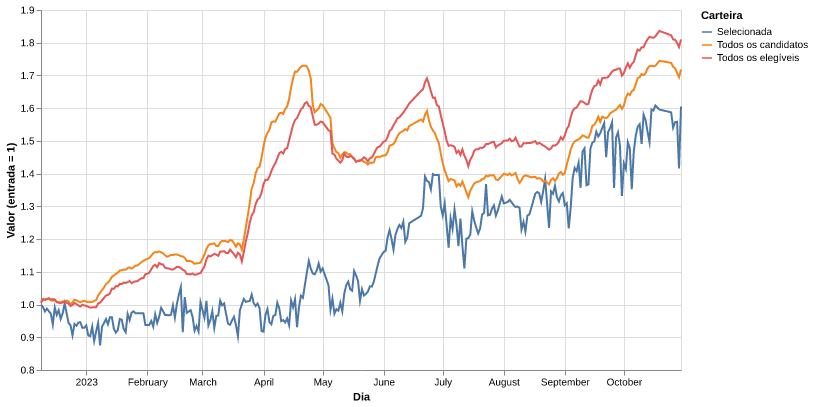

In [10]:
groups = {"selected": selected, "candidates": candidates, "eligible": eligible}
paths = benchmark_paths(prices, groups)
paths_text = paths.with_columns(pl.col("portfolio").replace_strict(PATH_LABELS, return_dtype=pl.String))

value_figure = (
    alt.Chart(paths_text)
    .mark_line()
    .encode(
        x=alt.X("date:T", title="Dia"),
        y=alt.Y("value:Q", title="Valor (entrada = 1)", scale=alt.Scale(zero=False)),
        color=alt.Color("portfolio:N", title="Carteira"),
    )
    .properties(width=640, height=360)
)
value_figure

## Detalhar a contribuição de cada item

A tabela mostra o múltiplo de cada item escolhido, do preço de entrada ao de saída, e quanto ele
contribui para o retorno bruto da carteira. Poucos itens com múltiplos altos podem explicar quase todo o
retorno.

In [11]:
contributions = item_contributions(selected, multiples, prices)

contributions_gt = (
    GT(contributions)
    .cols_align("left", columns=["name", "rarity"])
    .tab_header(title="Contribuição de Cada Item da Carteira — CS:GO")
    .fmt_percent(columns=["roi", "contribution"], decimals=1, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .fmt_number(columns=["entry_price", "exit_price", "multiple"], decimals=2, sep_mark=SEP_MARK, dec_mark=DEC_MARK)
    .cols_label(
        name="Item",
        rarity="Raridade",
        roi="ROI de treino",
        entry_price="Preço de entrada (US$)",
        exit_price="Preço de saída (US$)",
        multiple="Múltiplo",
        contribution="Contribuição ao retorno bruto",
    )
    .tab_source_note(
        "Múltiplo: preço de saída sobre preço de entrada, ambos medianas dos últimos preços observados. "
        "Contribuição: (múltiplo - 1) dividido pelo número de itens, antes da taxa de venda."
    )
)
contributions_gt

"Múltiplo: preço de saída sobre preço de entrada, ambos medianas dos últimos preços observados. Contribuição: (múltiplo - 1) dividido pelo número de itens, antes da taxa de venda."


## Exportar a carteira em Parquet, as tabelas em LaTeX e o gráfico em PNG

As linhas diárias e o resumo ficam em Parquet para análises posteriores. As tabelas e o gráfico são
gravados juntos, para que a tese use resultados da mesma execução.

In [12]:
for path in (args.buy_and_hold, args.output):
    path.parent.mkdir(parents=True, exist_ok=True)
    print(f"Written {path}")

rows.write_parquet(args.buy_and_hold)
metrics.write_parquet(args.output)

tables = {
    "portfolio": portfolio_gt,
    "portfolio_thresholds": thresholds_gt,
    "portfolio_rarity": rarity_gt,
    "portfolio_benchmarks": benchmarks_gt,
    "portfolio_sweep": sweep_gt,
    "portfolio_items": contributions_gt,
}

write_outputs(tables, {"portfolio_value": value_figure}, args.tables, args.images, WIDE_TABLES)

Written /mnt/external/projects/thesis/files/buy_and_hold.parquet
Written /mnt/external/projects/thesis/files/portfolio.parquet
Written /mnt/external/projects/thesis/output/tables/tex/portfolio.tex
Written /mnt/external/projects/thesis/output/tables/html/portfolio.html
Written /mnt/external/projects/thesis/output/tables/tex/portfolio_thresholds.tex
Written /mnt/external/projects/thesis/output/tables/html/portfolio_thresholds.html
Written /mnt/external/projects/thesis/output/tables/tex/portfolio_rarity.tex
Written /mnt/external/projects/thesis/output/tables/html/portfolio_rarity.html
Written /mnt/external/projects/thesis/output/tables/tex/portfolio_benchmarks.tex
Written /mnt/external/projects/thesis/output/tables/html/portfolio_benchmarks.html
Written /mnt/external/projects/thesis/output/tables/tex/portfolio_sweep.tex
Written /mnt/external/projects/thesis/output/tables/html/portfolio_sweep.html
Written /mnt/external/projects/thesis/output/tables/tex/portfolio_items.tex
Written /mnt/exte